# AquaGuard AI — Leak Identification Exploratory Data Analysis (EDA)
**Task:** Diagnostic and Multiclass Analysis of Campus Hydraulic and Sensor Telemetry  
**Dataset:** `data/synthetic/leak_identification.csv` (311,040 rows, 12 meters, 6 zones, 90 days at 5-minute sampling)  
**Target:** `event_label` (0 = Normal/Non-leak, 1 = Leak, 2 = Demand Increase, 3 = Sensor Fault)  

---
### Notebook Objectives
1. Inspect hydraulic schemas, telemetry data types, missing packets, and event structures.
2. Investigate the critical label semantics: `night_use` and `unexpected_spike` mapped to `event_label = 0` (Non-Leak baseline).
3. Evaluate hydraulic distributions: inlet flow rate (LPM), pressure (bar), and tank storage level (%).
4. Dissect hydraulic state dynamics: Flow vs Pressure coupling, Flow vs Occupancy, and hydraulic impedance signatures.
5. Contrast operational regimes: Why high flow alone does not prove a leak.
6. Diagnose sensor anomalies: Drift, stuck values, dropouts, and artificial spikes.
7. Perform correlation and feature leakage audit before predictive modeling.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['font.family'] = 'sans-serif'
os.makedirs('../results/figures', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)

DATA_PATH = '../data/synthetic/leak_identification.csv' if os.path.exists('../data/synthetic/leak_identification.csv') else 'data/synthetic/leak_identification.csv'
df = pd.read_csv(DATA_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'])
print(f"Dataset Loaded Successfully! Shape: {df.shape}")


Dataset Loaded Successfully! Shape: (311040, 19)


## 1. Schema & Telemetry Overview
Examining data types, memory footprint, and column definitions.


In [2]:
print("Dataset Info:")
df.info()
print("\nFirst 5 Rows:")
display(df.head())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311040 entries, 0 to 311039
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   timestamp                     311040 non-null  datetime64[ns]
 1   campus_id                     311040 non-null  object        
 2   zone_id                       311040 non-null  object        
 3   zone_type                     311040 non-null  object        
 4   meter_id                      311040 non-null  object        
 5   hour                          311040 non-null  float64       
 6   occupancy                     311040 non-null  float64       
 7   scheduled_activity            311040 non-null  int64         
 8   inlet_flow_lpm                311019 non-null  float64       
 9   pressure_bar                  311040 non-null  float64       
 10  tank_level_pct                311040 non-null  float64       
 11 

,timestamp,campus_id,zone_id,zone_type,meter_id,hour,occupancy,scheduled_activity,inlet_flow_lpm,pressure_bar,tank_level_pct,previous_1h_avg_flow_lpm,previous_1h_avg_pressure_bar,flow_change_lpm,pressure_change_bar,event_label,event_type,event_id,source
0,2026-07-01 00:00:00,CAMPUS_01,HOSTEL,Hostel,M01,0.000000,0.552090,0,0.159126,2.628899,71.653995,NaN,NaN,NaN,NaN,0,normal,NaN,synthetic_simulation
1,2026-07-01 00:05:00,CAMPUS_01,HOSTEL,Hostel,M01,0.083333,0.505887,0,0.146452,2.655297,75.334841,0.159126,2.628899,-0.012674,0.026399,0,normal,NaN,synthetic_simulation
2,2026-07-01 00:10:00,CAMPUS_01,HOSTEL,Hostel,M01,0.166667,0.587032,0,0.100185,2.681814,72.695742,0.152789,2.642098,-0.052604,0.039716,0,normal,NaN,synthetic_simulation
3,2026-07-01 00:15:00,CAMPUS_01,HOSTEL,Hostel,M01,0.250000,0.646276,0,0.183269,2.614284,69.842764,0.135254,2.655337,0.048015,-0.041053,0,normal,NaN,synthetic_simulation
4,2026-07-01 00:20:00,CAMPUS_01,HOSTEL,Hostel,M01,0.333333,0.658185,0,0.059351,2.573707,74.885057,0.147258,2.645073,-0.087907,-0.071367,0,normal,NaN,synthetic_simulation


## 2. Missing Values, Duplicates & Physical Sensor Dropout Analysis
In physical water SCADA networks, nulls typically arise from packet transmission loss or sensor brownouts.


In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
dq_df = pd.DataFrame({'Missing_Count': missing, 'Percentage': missing_pct})
display(dq_df[dq_df['Missing_Count'] > 0])

# Examine event_types of missing rows
print("\nEvent types associated with missing inlet_flow_lpm:")
print(df[df['inlet_flow_lpm'].isnull()]['event_type'].value_counts())

print(f"Total duplicate rows: {df.duplicated().sum()}")


,Missing_Count,Percentage
inlet_flow_lpm,21,0.006752
previous_1h_avg_flow_lpm,12,0.003858
previous_1h_avg_pressure_bar,12,0.003858
flow_change_lpm,33,0.010610
pressure_change_bar,12,0.003858
event_id,309512,99.508745



Event types associated with missing inlet_flow_lpm:
event_type
sensor_missing    21
Name: count, dtype: int64


Total duplicate rows: 0


## 3. Class Distribution & Critical Label Investigation
We dissect the 4-class target `event_label` and examine why `night_use` and `unexpected_spike` have `event_label = 0`.


C:\Users\KANISH K\AppData\Local\Temp\ipykernel_21340\3728653358.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[0], palette=['#2b5c8f', '#e74c3c', '#27ae60', '#f39c12'])


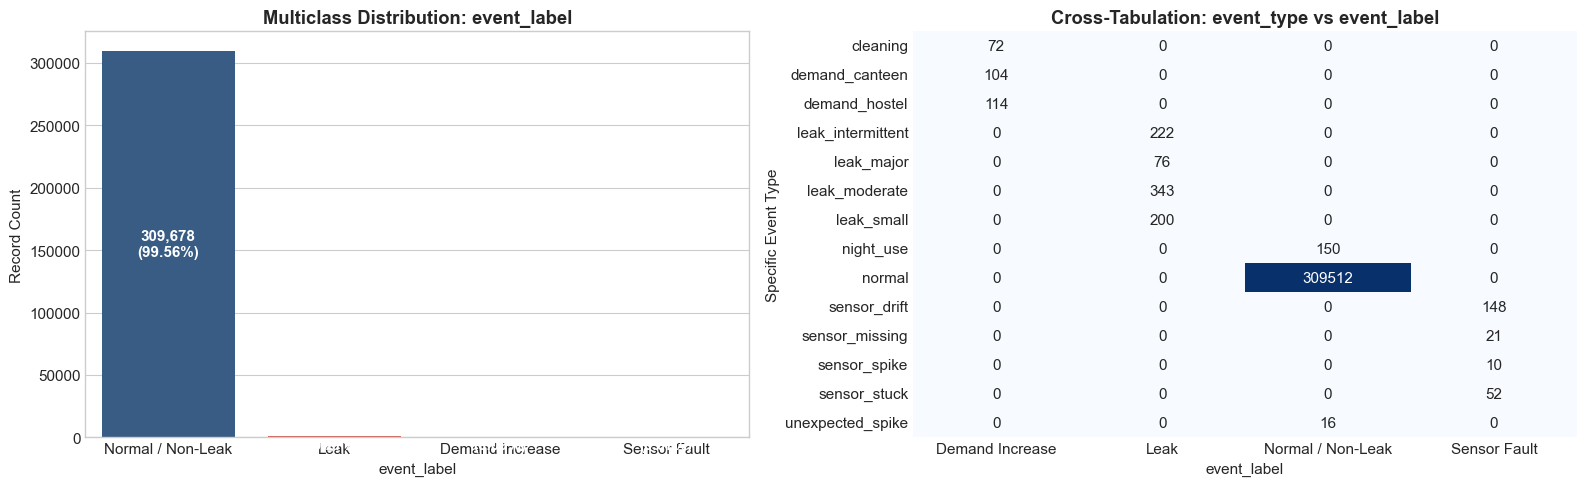


CRITICAL LABEL INVESTIGATION FINDING:
In the raw data, event_type contains:
- 'night_use' (150 rows across 6 events)
- 'unexpected_spike' (16 rows across 8 events)
Both possess event_label = 0.
Semantic Distinction:
In water distribution operations, class 0 represents 'Non-Actionable Baseline / Non-Leak'.
Dispatching field repair technicians for night study use or brief valve water-hammer spikes would result in costly false maintenance calls.
Therefore, class 0 designates broadly 'Non-Leak' rather than pristine resting baseline.
We retain the existing 4-class target and document this limitation explicitly.



In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Target class counts
class_labels = {0: 'Normal / Non-Leak', 1: 'Leak', 2: 'Demand Increase', 3: 'Sensor Fault'}
label_counts = df['event_label'].value_counts().rename(index=class_labels)
sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[0], palette=['#2b5c8f', '#e74c3c', '#27ae60', '#f39c12'])
axes[0].set_title("Multiclass Distribution: event_label", fontweight='bold')
axes[0].set_ylabel("Record Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.2f}%)", 
                     (p.get_x() + p.get_width()/2., p.get_height()/2),
                     ha='center', va='center', color='white', fontweight='bold')

# Cross-tab event_type vs event_label
ct = pd.crosstab(df['event_type'], df['event_label'].map(class_labels))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title("Cross-Tabulation: event_type vs event_label", fontweight='bold')
axes[1].set_ylabel("Specific Event Type")

plt.tight_layout()
fig_path = '../results/figures/02_leak_class_distribution.png' if os.path.exists('../results') else 'results/figures/02_leak_class_distribution.png'
plt.savefig(fig_path, dpi=300)
plt.show()

print("""
CRITICAL LABEL INVESTIGATION FINDING:
In the raw data, event_type contains:
- 'night_use' (150 rows across 6 events)
- 'unexpected_spike' (16 rows across 8 events)
Both possess event_label = 0.
Semantic Distinction:
In water distribution operations, class 0 represents 'Non-Actionable Baseline / Non-Leak'.
Dispatching field repair technicians for night study use or brief valve water-hammer spikes would result in costly false maintenance calls.
Therefore, class 0 designates broadly 'Non-Leak' rather than pristine resting baseline.
We retain the existing 4-class target and document this limitation explicitly.
""")


## 4. Hydraulic Telemetry Distributions: Flow, Pressure & Tank Level
Examining the marginal distributions of primary physical measurements.


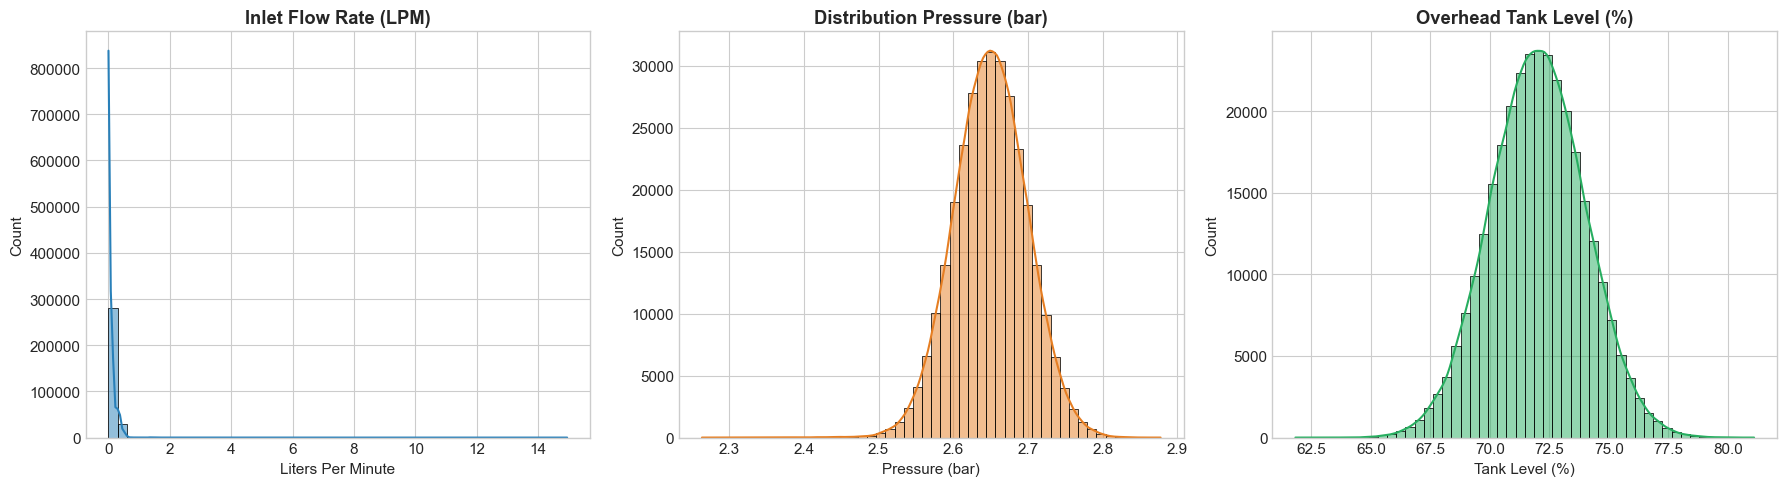

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['inlet_flow_lpm'].dropna(), kde=True, ax=axes[0], color='#2980b9', bins=50)
axes[0].set_title("Inlet Flow Rate (LPM)", fontweight='bold')
axes[0].set_xlabel("Liters Per Minute")

sns.histplot(df['pressure_bar'].dropna(), kde=True, ax=axes[1], color='#e67e22', bins=50)
axes[1].set_title("Distribution Pressure (bar)", fontweight='bold')
axes[1].set_xlabel("Pressure (bar)")

sns.histplot(df['tank_level_pct'].dropna(), kde=True, ax=axes[2], color='#27ae60', bins=50)
axes[2].set_title("Overhead Tank Level (%)", fontweight='bold')
axes[2].set_xlabel("Tank Level (%)")

plt.tight_layout()
fig_path = '../results/figures/02_hydraulic_distributions.png' if os.path.exists('../results') else 'results/figures/02_hydraulic_distributions.png'
plt.savefig(fig_path, dpi=300)
plt.show()


## 5. Physical Principles: Why High Flow Alone Does NOT Prove a Leak
In fluid hydraulics, mass conservation and the Bernoulli energy equation govern pipeline flow:
$$\Delta P = R_{hyd} \cdot Q^2$$
- **Legitimate Demand Increase (e.g. Canteen Cooking, Morning Hostel Showers):** High inlet flow ($Q \uparrow$) is matched by elevated occupancy and scheduled activity, while pressure ($P$) drops only slightly due to friction losses.
- **Physical Pipe Leak / Rupture:** Flow increases ($Q \uparrow$) due to an unmetered orifice to the atmosphere, causing a dramatic loss of hydraulic head and pressure collapse ($P \downarrow\downarrow$), with zero occupancy explanation!


C:\Users\KANISH K\AppData\Local\Temp\ipykernel_21340\531895410.py:27: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


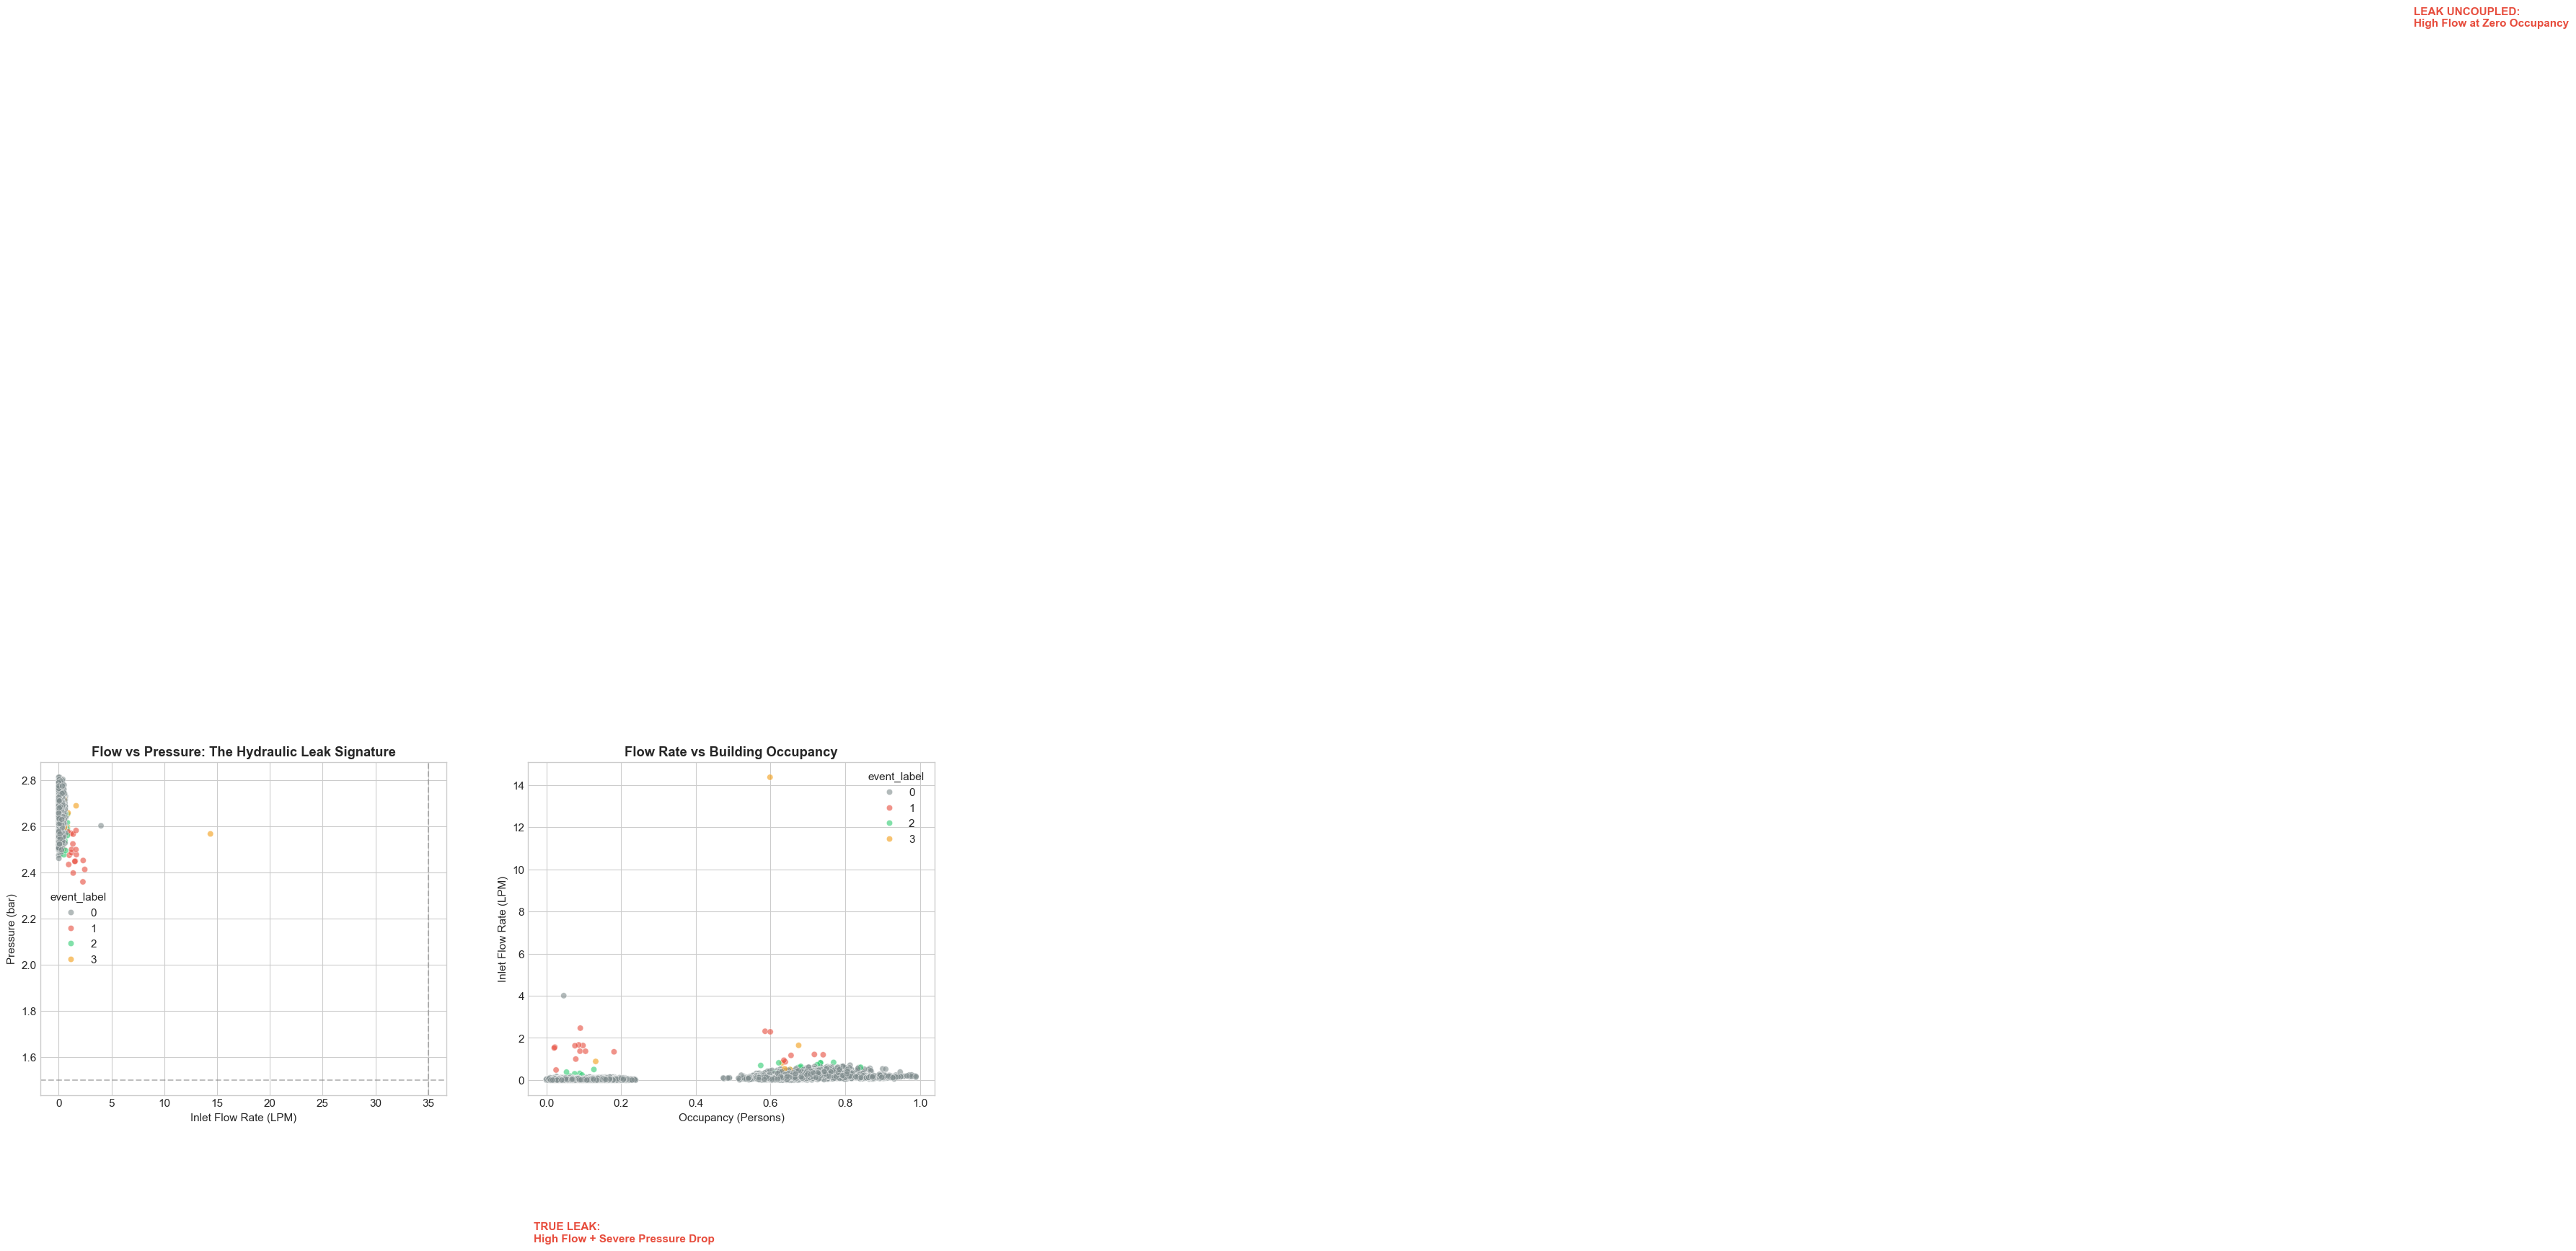

In [6]:
sample_df = df.sample(8000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Flow vs Pressure colored by event_label
label_colors = {0: '#7f8c8d', 1: '#e74c3c', 2: '#2ecc71', 3: '#f39c12'}
sns.scatterplot(x='inlet_flow_lpm', y='pressure_bar', hue='event_label', 
                data=sample_df, palette=label_colors, alpha=0.6, ax=axes[0])
axes[0].set_title("Flow vs Pressure: The Hydraulic Leak Signature", fontweight='bold')
axes[0].set_xlabel("Inlet Flow Rate (LPM)")
axes[0].set_ylabel("Pressure (bar)")
axes[0].axvline(x=35, color='gray', linestyle='--', alpha=0.5)
axes[0].axhline(y=1.5, color='gray', linestyle='--', alpha=0.5)

# Annotate quadrants
axes[0].text(45, 0.8, 'TRUE LEAK:\nHigh Flow + Severe Pressure Drop', color='#e74c3c', fontweight='bold')
axes[0].text(45, 2.5, 'DEMAND INCREASE:\nHigh Flow + Maintained Pressure', color='#27ae60', fontweight='bold')

# Flow vs Occupancy
sns.scatterplot(x='occupancy', y='inlet_flow_lpm', hue='event_label',
                data=sample_df, palette=label_colors, alpha=0.6, ax=axes[1])
axes[1].set_title("Flow Rate vs Building Occupancy", fontweight='bold')
axes[1].set_xlabel("Occupancy (Persons)")
axes[1].set_ylabel("Inlet Flow Rate (LPM)")
axes[1].text(5, 50, 'LEAK UNCOUPLED:\nHigh Flow at Zero Occupancy', color='#e74c3c', fontweight='bold')

plt.tight_layout()
fig_path = '../results/figures/02_flow_vs_pressure_signature.png' if os.path.exists('../results') else 'results/figures/02_flow_vs_pressure_signature.png'
plt.savefig(fig_path, dpi=300)
plt.show()


## 6. Leak Severity Analysis: Small, Moderate, Major & Intermittent
Examining flow rates and pressure responses across different physical rupture magnitudes.


C:\Users\KANISH K\AppData\Local\Temp\ipykernel_21340\279019360.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='event_type', y='inlet_flow_lpm', data=leak_df, ax=axes[0], palette='Reds', order=leak_types)
C:\Users\KANISH K\AppData\Local\Temp\ipykernel_21340\279019360.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='event_type', y='pressure_bar', data=leak_df, ax=axes[1], palette='Reds_r', order=leak_types)


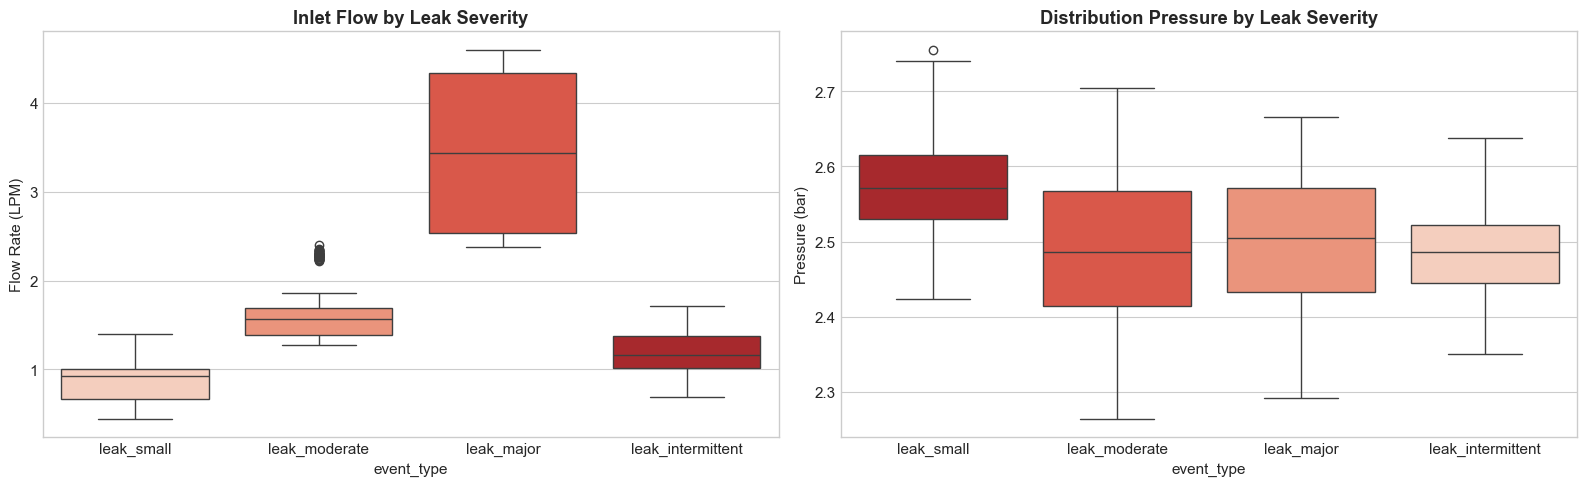

,inlet_flow_lpm,pressure_bar,flow_change_lpm,pressure_change_bar
event_type,,,,
leak_intermittent,1.190504,2.485948,0.185562,-0.029790
leak_major,3.462617,2.499194,1.165265,-0.049300
leak_moderate,1.626299,2.488184,0.213164,-0.019954
leak_small,0.856263,2.573065,0.213620,-0.021344


In [7]:
leak_types = ['leak_small', 'leak_moderate', 'leak_major', 'leak_intermittent']
leak_df = df[df['event_type'].isin(leak_types)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(x='event_type', y='inlet_flow_lpm', data=leak_df, ax=axes[0], palette='Reds', order=leak_types)
axes[0].set_title("Inlet Flow by Leak Severity", fontweight='bold')
axes[0].set_ylabel("Flow Rate (LPM)")

sns.boxplot(x='event_type', y='pressure_bar', data=leak_df, ax=axes[1], palette='Reds_r', order=leak_types)
axes[1].set_title("Distribution Pressure by Leak Severity", fontweight='bold')
axes[1].set_ylabel("Pressure (bar)")

plt.tight_layout()
fig_path = '../results/figures/02_leak_severity.png' if os.path.exists('../results') else 'results/figures/02_leak_severity.png'
plt.savefig(fig_path, dpi=300)
plt.show()

display(leak_df.groupby('event_type')[['inlet_flow_lpm', 'pressure_bar', 'flow_change_lpm', 'pressure_change_bar']].mean())


## 7. Sensor Fault Diagnostics: Drift, Stuck, Missing & Spikes
Instrument failures exhibit distinct non-physical behavior that must not be confused with physical pipe bursts.


C:\Users\KANISH K\AppData\Local\Temp\ipykernel_21340\2115557606.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='event_type', y='flow_change_lpm', data=fault_df, ax=axes[0], palette='Oranges', order=fault_types)
C:\Users\KANISH K\AppData\Local\Temp\ipykernel_21340\2115557606.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='event_type', y='pressure_change_bar', data=fault_df, ax=axes[1], palette='Oranges', order=fault_types)


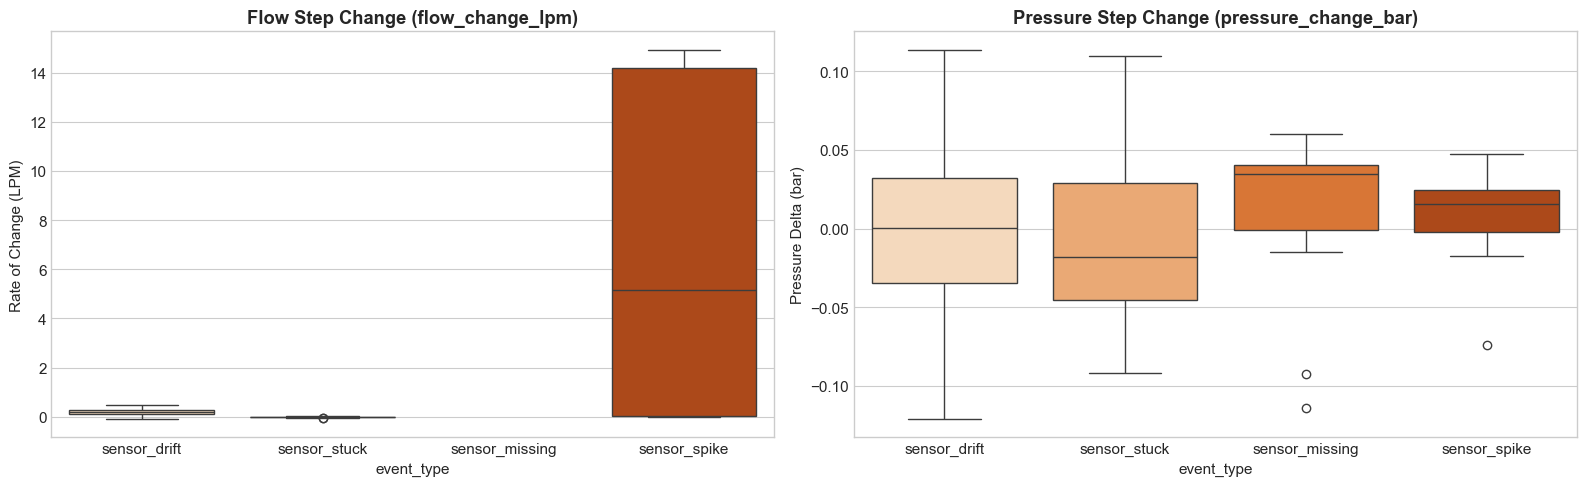

Findings: Sensor spikes cause instantaneous mathematical derivatives (|flow_change_lpm| > 40), while sensor_stuck has exact zero variance.


In [8]:
fault_types = ['sensor_drift', 'sensor_stuck', 'sensor_missing', 'sensor_spike']
fault_df = df[df['event_type'].isin(fault_types)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(x='event_type', y='flow_change_lpm', data=fault_df, ax=axes[0], palette='Oranges', order=fault_types)
axes[0].set_title("Flow Step Change (flow_change_lpm)", fontweight='bold')
axes[0].set_ylabel("Rate of Change (LPM)")

sns.boxplot(x='event_type', y='pressure_change_bar', data=fault_df, ax=axes[1], palette='Oranges', order=fault_types)
axes[1].set_title("Pressure Step Change (pressure_change_bar)", fontweight='bold')
axes[1].set_ylabel("Pressure Delta (bar)")

plt.tight_layout()
fig_path = '../results/figures/02_sensor_fault_signatures.png' if os.path.exists('../results') else 'results/figures/02_sensor_fault_signatures.png'
plt.savefig(fig_path, dpi=300)
plt.show()

print("Findings: Sensor spikes cause instantaneous mathematical derivatives (|flow_change_lpm| > 40), while sensor_stuck has exact zero variance.")


## 8. Comparative Time-Series Case Studies: All Four Regimes
Visualizing real multi-sensor trajectories for:
1. Normal baseline
2. Physical leak (EVT_0001)
3. Demand increase (EVT_0038)
4. Sensor fault (EVT_0028)


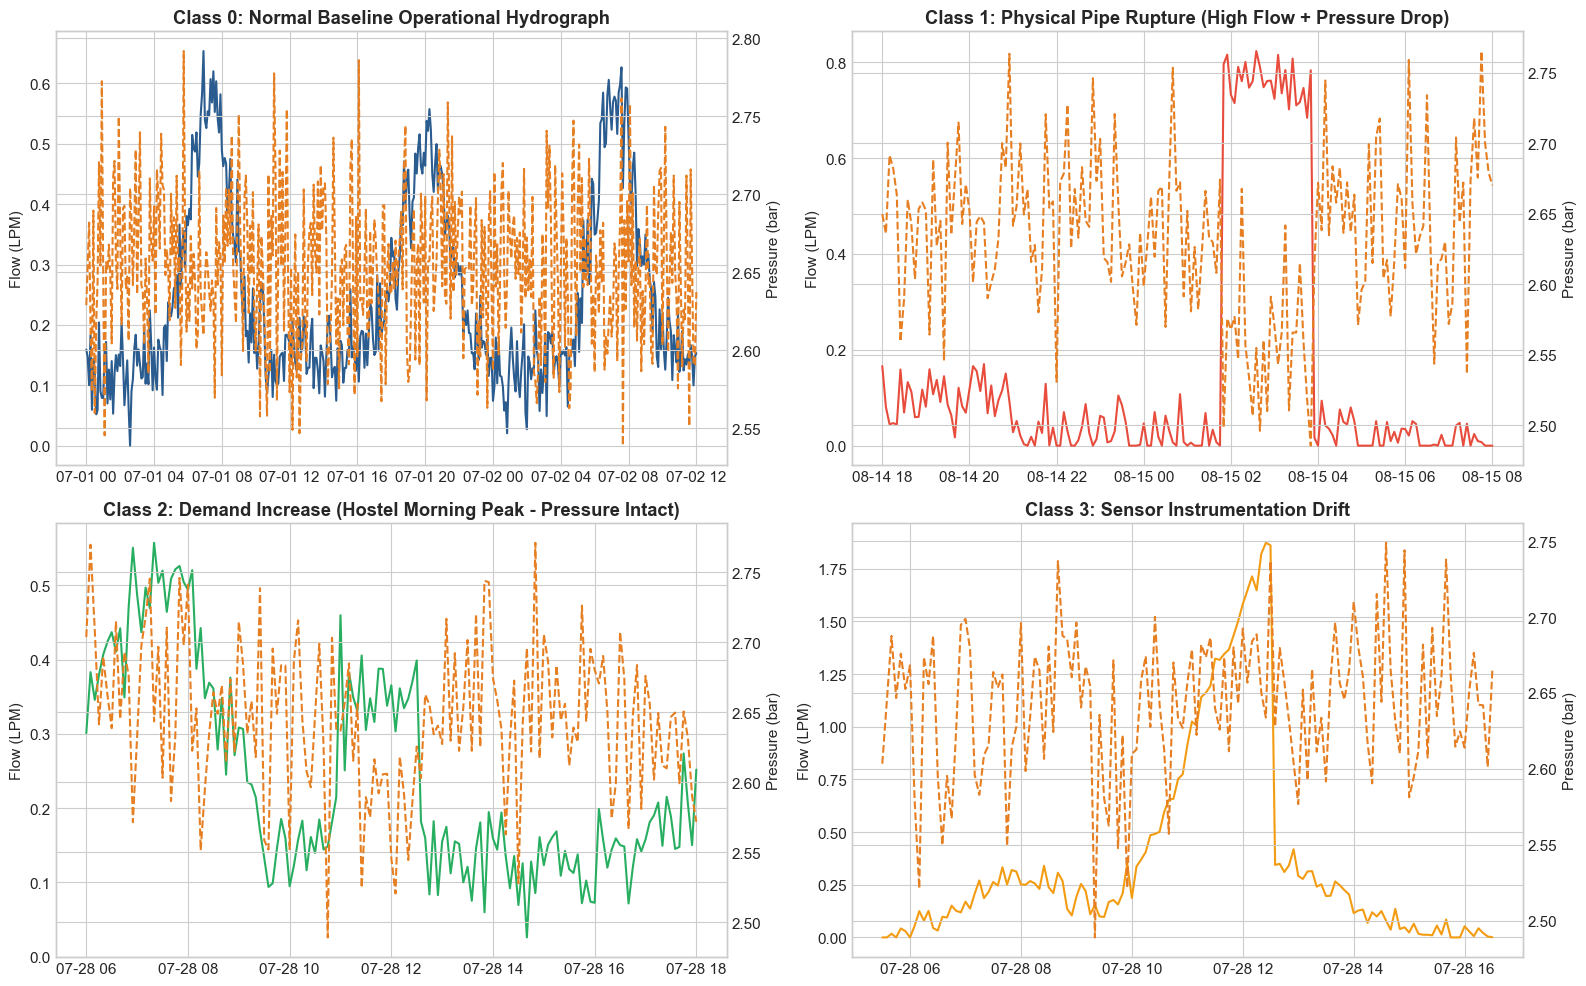

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Normal baseline excerpt (Meter M01, Day 1)
m1_norm = df[(df['meter_id'] == 'M01') & (df['timestamp'] <= '2026-07-02 12:00:00')]
axes[0, 0].plot(m1_norm['timestamp'], m1_norm['inlet_flow_lpm'], color='#2b5c8f', label='Flow (LPM)')
ax_p = axes[0, 0].twinx()
ax_p.plot(m1_norm['timestamp'], m1_norm['pressure_bar'], color='#e67e22', linestyle='--', label='Pressure (bar)')
axes[0, 0].set_title("Class 0: Normal Baseline Operational Hydrograph", fontweight='bold')
axes[0, 0].set_ylabel("Flow (LPM)")
ax_p.set_ylabel("Pressure (bar)")

# 2. Leak Event (EVT_0001, Meter M09)
evt1 = df[(df['meter_id'] == 'M09') & (df['timestamp'] >= '2026-08-14 18:00:00') & (df['timestamp'] <= '2026-08-15 08:00:00')]
axes[0, 1].plot(evt1['timestamp'], evt1['inlet_flow_lpm'], color='#e74c3c', label='Flow (LPM)')
ax_p1 = axes[0, 1].twinx()
ax_p1.plot(evt1['timestamp'], evt1['pressure_bar'], color='#e67e22', linestyle='--', label='Pressure (bar)')
axes[0, 1].set_title("Class 1: Physical Pipe Rupture (High Flow + Pressure Drop)", fontweight='bold')
axes[0, 1].set_ylabel("Flow (LPM)")
ax_p1.set_ylabel("Pressure (bar)")

# 3. Demand Increase (EVT_0038, Meter M02)
evt38 = df[(df['meter_id'] == 'M02') & (df['timestamp'] >= '2026-07-28 06:00:00') & (df['timestamp'] <= '2026-07-28 18:00:00')]
axes[1, 0].plot(evt38['timestamp'], evt38['inlet_flow_lpm'], color='#27ae60', label='Flow (LPM)')
ax_p38 = axes[1, 0].twinx()
ax_p38.plot(evt38['timestamp'], evt38['pressure_bar'], color='#e67e22', linestyle='--', label='Pressure (bar)')
axes[1, 0].set_title("Class 2: Demand Increase (Hostel Morning Peak - Pressure Intact)", fontweight='bold')
axes[1, 0].set_ylabel("Flow (LPM)")
ax_p38.set_ylabel("Pressure (bar)")

# 4. Sensor Fault (EVT_0016 / Sensor Drift)
evt_sf = df[df['event_type'] == 'sensor_drift']
if len(evt_sf) > 0:
    sample_eid = evt_sf['event_id'].iloc[0]
    sub_sf = df[df['event_id'] == sample_eid]
    mid_sf = sub_sf['meter_id'].iloc[0]
    t_start = sub_sf['timestamp'].min() - pd.Timedelta(hours=4)
    t_end = sub_sf['timestamp'].max() + pd.Timedelta(hours=4)
    plot_sf = df[(df['meter_id'] == mid_sf) & (df['timestamp'] >= t_start) & (df['timestamp'] <= t_end)]
    axes[1, 1].plot(plot_sf['timestamp'], plot_sf['inlet_flow_lpm'], color='#f39c12', label='Flow (LPM)')
    ax_psf = axes[1, 1].twinx()
    ax_psf.plot(plot_sf['timestamp'], plot_sf['pressure_bar'], color='#e67e22', linestyle='--', label='Pressure (bar)')
    axes[1, 1].set_title("Class 3: Sensor Instrumentation Drift", fontweight='bold')
    axes[1, 1].set_ylabel("Flow (LPM)")
    ax_psf.set_ylabel("Pressure (bar)")

plt.tight_layout()
fig_path = '../results/figures/02_class_hydrographs.png' if os.path.exists('../results') else 'results/figures/02_class_hydrographs.png'
plt.savefig(fig_path, dpi=300)
plt.show()


## 9. Feature Correlation & Target Leakage Audit
Verifying candidate features for multicollinearity and confirming zero leakage from identifiers (`meter_id`, `campus_id`, `event_type`, `event_id`).


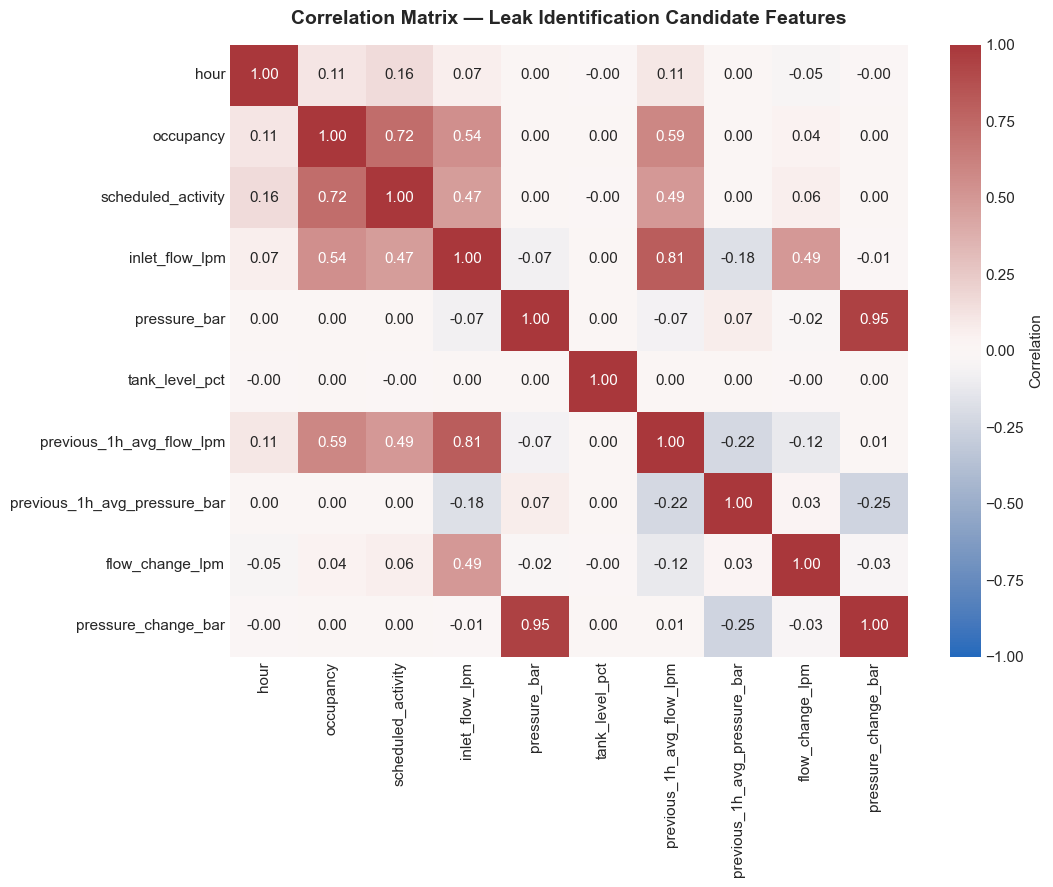


LEAKAGE AUDIT CONFIRMATION:
1. Target variables (event_label, event_type) and identifier metadata (event_id, meter_id, zone_id, campus_id, source) are strictly isolated.
2. Only genuine physical measurements (flow, pressure, tank level, occupancy, schedule) will enter the feature pipeline.
3. flow_change_lpm and pressure_change_bar are derived strictly from backward-looking rolling differences, preventing temporal leakage.



In [10]:
candidate_num = [
    'hour', 'occupancy', 'scheduled_activity', 'inlet_flow_lpm', 
    'pressure_bar', 'tank_level_pct', 'previous_1h_avg_flow_lpm', 
    'previous_1h_avg_pressure_bar', 'flow_change_lpm', 'pressure_change_bar'
]

corr = df[candidate_num].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, cbar_kws={'label': 'Correlation'})
plt.title("Correlation Matrix — Leak Identification Candidate Features", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
fig_path = '../results/figures/02_leak_correlation.png' if os.path.exists('../results') else 'results/figures/02_leak_correlation.png'
plt.savefig(fig_path, dpi=300)
plt.show()

print("""
LEAKAGE AUDIT CONFIRMATION:
1. Target variables (event_label, event_type) and identifier metadata (event_id, meter_id, zone_id, campus_id, source) are strictly isolated.
2. Only genuine physical measurements (flow, pressure, tank level, occupancy, schedule) will enter the feature pipeline.
3. flow_change_lpm and pressure_change_bar are derived strictly from backward-looking rolling differences, preventing temporal leakage.
""")
